# Sri Lankan Mobile Phone Price Prediction

During the development of this project, I used Claude AI as a supporting tool to improve certain parts of the code and fix some errors. However, the entire project was not generated by AI. I reviewed, tested, and made the necessary modifications to the code myself.

**Contents**

1. Part 1: Data Understanding  
2. Part 2: Data Preprocessing  
3. Part 3: Baseline And Bagging  
4. Part 4: Boosting  
5. Part 5: Stacking  
6. Part 6: Hybrid Rf Ann  
7. Part 7: Model Comparison  
8. Part 8: Fair Price Checker  
9. Part 9: Research Discussion  


# 01 - Data understanding and EDA
**Project:** Sri Lankan mobile phone price prediction with ensemble learning (CM4371).
**Goal of this notebook:** understand the raw 5,158-row CSV *before* modelling: structure, missing values, data quality problems and what drives price.

The target is the **advertised / catalogue price in LKR**: ikman.lk values are sellers' asking prices, Dialog values are retail catalogue prices. It is *not* a confirmed sold price.


In [1]:
import sys, warnings
sys.path.append("..")                      # lets the notebook import the reusable code in ../src
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, preprocess as P, models as M
from src.evaluate import regression_metrics, permutation_table
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
config.PLOT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the raw CSV (never modified)
loads the original mobile phone dataset and examines its basic structure. checks the number of records, available columns, data types, and missing values to understand the quality of the raw data.

In [2]:
raw = pd.read_csv(config.RAW_CSV)
print("rows, columns:", raw.shape)
raw.head()

rows, columns: (5158, 19)


,id,title,brand,model,price,price_raw,condition,storage,ram,location,description,detail_brand,detail_model,detail_condition,seller_name,posted_date,ad_url,is_member,is_featured
0,1,Apple iPhone 15 (Brand New),Apple,iPhone 15,200000,"Rs 200,000",Brand New,NaN,NaN,Kandy,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/apple-iphone-15-brand-n...,True,False
1,2,Samsung Galaxy A56 5G 8GB 256GB (Brand New),Samsung,Galaxy A56 5G 8GB 256GB,95989,"Rs 95,989",Brand New,256GB,8GB,Colombo,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/samsung-galaxy-a56-5g-8...,True,False
2,3,Apple iPhone 14 128GB (Used),Apple,iPhone 14 128GB,119999,"Rs 119,999",Used,128GB,NaN,Colombo,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/apple-iphone-14-128gb-u...,True,True
3,4,Infinix Hot 60i 128GB 6GBRam Blue (Brand New),Infinix,Hot 60i 128GB 6GBRam Blue,39990,"Rs 39,990",Brand New,128GB,6GB,Colombo,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/infinix-hot-60i-128gb-6...,True,False
4,5,Apple iPhone 14 Pro (Used),Apple,iPhone 14 Pro,170000,"Rs 170,000",Used,NaN,NaN,Kurunegala,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/apple-iphone-14-pro-use...,False,False


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5158 entries, 0 to 5157
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                5158 non-null   int64  
 1   title             5158 non-null   str    
 2   brand             5158 non-null   str    
 3   model             5158 non-null   str    
 4   price             5158 non-null   int64  
 5   price_raw         5158 non-null   str    
 6   condition         5158 non-null   str    
 7   storage           3354 non-null   str    
 8   ram               450 non-null    str    
 9   location          5157 non-null   str    
 10  description       0 non-null      float64
 11  detail_brand      0 non-null      float64
 12  detail_model      0 non-null      float64
 13  detail_condition  0 non-null      float64
 14  seller_name       0 non-null      float64
 15  posted_date       0 non-null      float64
 16  ad_url            5158 non-null   str    
 17  is_mem

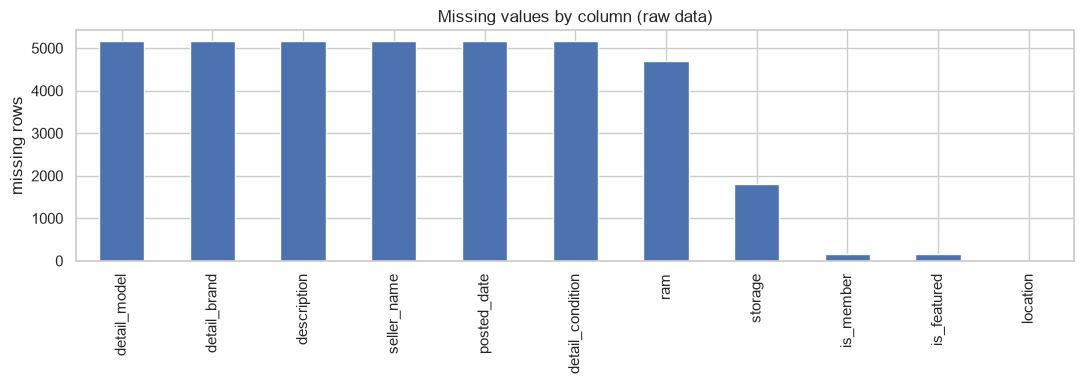

In [4]:
miss = raw.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss.plot(kind="bar", figsize=(11, 4), color="#4C72B0")
plt.title("Missing values by column (raw data)"); plt.ylabel("missing rows"); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "01_missing_values.png", dpi=150); plt.show()

## 2. Which rows are ikman and which are Dialog?
This section identifies the source of each mobile phone record using its advertisement URL. It separates ikman and Dialog records and checks any records that could not be identified automatically.

In [5]:
src_guess = P.derive_source(raw)
print(src_guess.value_counts())
raw[src_guess == "Unknown"][["id", "title", "price", "condition", "location", "ad_url"]].head(15)

ikman     5124
Dialog      34
Name: count, dtype: int64


,id,title,price,condition,location,ad_url


## 3. RAM / storage quality check
This section checks the RAM and storage values in the dataset. Some records may have incorrect or swapped values, so the specifications are re-extracted from the available phone details to improve data accuracy.

In [6]:
parsed = pd.DataFrame(
    [P.parse_specs(r.get("title"), r.get("model"), r.get("storage"), r.get("ram"), r.get("detail_model"))
     for _, r in raw.iterrows()], columns=["ram_gb", "storage_gb"], index=raw.index)
csv_storage = pd.to_numeric(raw["storage"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
wrong = raw[(csv_storage <= 24)].join(parsed)
print(f"{len(wrong)} rows where the CSV 'storage' value is <= 24GB (probably RAM)")
wrong[["title", "storage", "ram", "ram_gb", "storage_gb"]].head(12)

964 rows where the CSV 'storage' value is <= 24GB (probably RAM)


,title,storage,ram,ram_gb,storage_gb
13,Realme C51 (4+4GB/128GB) (Used),4GB,4GB,4.00,128.00
25,Tecno Pop 7 (2+2GB/64GB) (Used),2GB,2GB,2.00,64.00
28,Google Pixel 7 8GB|128GB|50MP (Brand New),8GB,8GB,8.00,128.00
29,Vivo X300 Pro 16GB 512GB (Used),16GB,NaN,16.00,512.00
35,Samsung Galaxy S24 Ultra 12GB | 512GB (Brand New),12GB,12GB,12.00,512.00
42,Samsung Galaxy S25 Plus 12GB | 256GB (Brand New),12GB,12GB,12.00,256.00
46,Samsung Galaxy S25 12GB | 256GB (Brand New),12GB,12GB,12.00,256.00
48,Samsung Galaxy S25 FE 8GB | 256GB (Brand New),8GB,8GB,8.00,256.00
59,LG Q52 4GB 64GB (Used),4GB,NaN,4.00,64.00
60,Samsung Galaxy A17 5G 8GB+256GB (Brand New),8GB,NaN,8.00,256.00


In [7]:
print("parsed RAM missing    :", parsed["ram_gb"].isna().mean().round(3))
print("parsed storage missing :", parsed["storage_gb"].isna().mean().round(3))

parsed RAM missing    : 0.767
parsed storage missing : 0.351


## 4. Clean in memory for EDA
This section applies the data-cleaning process to prepare the dataset for exploratory data analysis. It handles incorrect specifications and source information while keeping the original CSV unchanged.

The full, saved cleaning (with the step-by-step row counts) is in notebook 02; here the same function is used so the EDA plots use correct RAM, storage and source values.

In [8]:
df, report = P.clean_dataset(raw, blank_url_source=config.BLANK_URL_SOURCE)
display(report) if "display" in globals() else print(report)
print(df.shape)
df.describe(include="all").T

27 suspicious prices flagged (kept unless drop_suspicious=True).
                      step  rows_after
0                 raw file        5158
1       drop missing price        5158
2          drop price <= 0        5158
3  drop duplicate listings        4432
4      final clean dataset        4432
(4432, 12)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,"4,432.00",NaN,NaN,NaN,"2,488.58","1,499.35",1.00,"1,179.75","2,439.50","3,771.25","5,158.00"
title,4432,2239,Apple iPhone 11 (Used),61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,4432,23,Apple,2079,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,4432,1099,apple iphone 11,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition,4432,3,Used,3322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
storage_gb,"2,819.00",NaN,NaN,NaN,205.44,117.25,4.00,128.00,256.00,256.00,"1,024.00"
ram_gb,"1,119.00",NaN,NaN,NaN,7.94,3.28,1.00,6.00,8.00,10.00,24.00
location,4432,27,Colombo,2206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,4432,2,ikman,4398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"4,432.00",NaN,NaN,NaN,"102,447.69","94,556.66","1,000.00","34,990.00","72,500.00","140,000.00","1,037,000.00"


## 5. Price distribution
This section explores the distribution of mobile phone prices in LKR. It compares the original price distribution with the log-transformed distribution to understand price variations and skewness.

skewness raw: 1.99 | log: -0.43


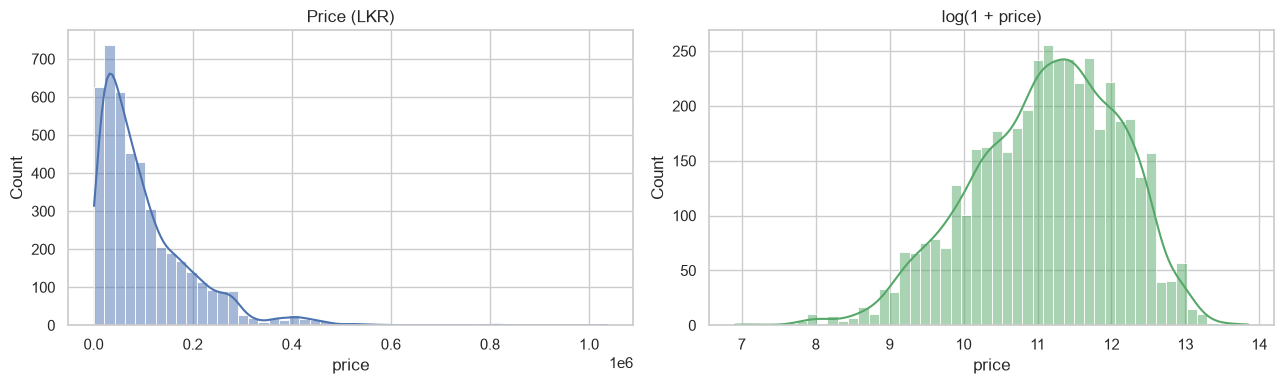

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], bins=50, kde=True, ax=ax[0], color="#4C72B0"); ax[0].set_title("Price (LKR)")
sns.histplot(np.log1p(df["price"]), bins=50, kde=True, ax=ax[1], color="#55A868"); ax[1].set_title("log(1 + price)")
print("skewness raw:", round(df["price"].skew(), 2), "| log:", round(np.log1p(df["price"]).skew(), 2))
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "01_price_distribution.png", dpi=150); plt.show()

## 6. Brand, condition, RAM, storage, source
This section explores how different features relate to mobile phone prices. It examines brand, device condition, RAM, storage capacity, data source, and location to identify possible price patterns.

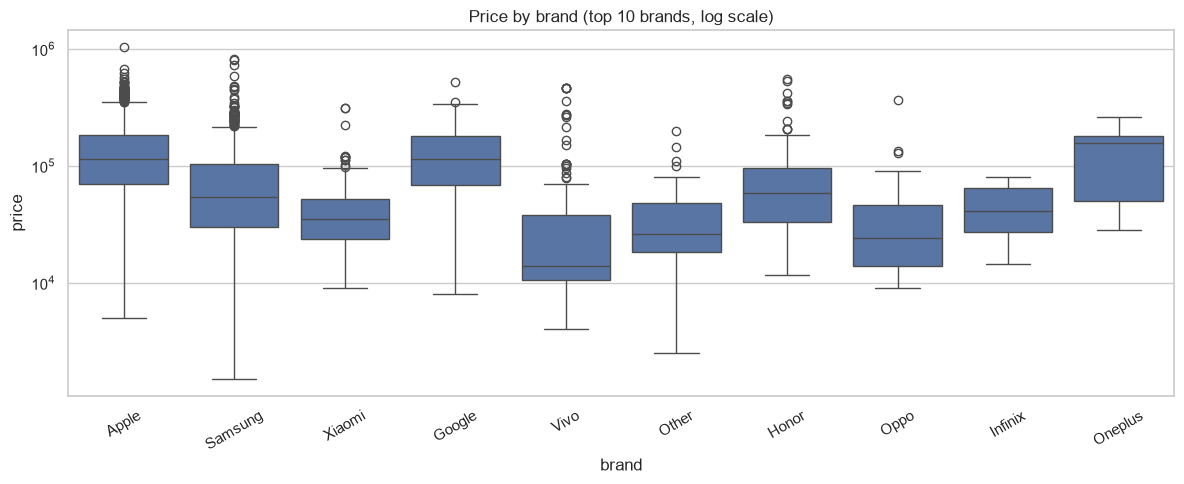

In [10]:
top = df["brand"].value_counts().head(10).index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[df["brand"].isin(top)], x="brand", y="price", order=top)
plt.yscale("log"); plt.title("Price by brand (top 10 brands, log scale)"); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "01_brand_vs_price.png", dpi=150); plt.show()

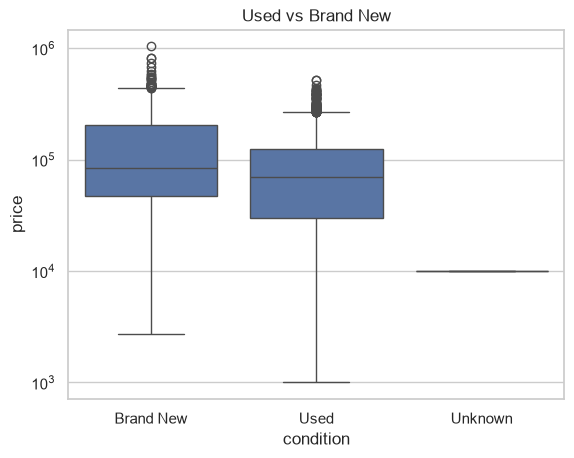

In [11]:
sns.boxplot(data=df, x="condition", y="price"); plt.yscale("log"); plt.title("Used vs Brand New")
plt.savefig(config.PLOT_DIR / "01_condition_vs_price.png", dpi=150); plt.show()

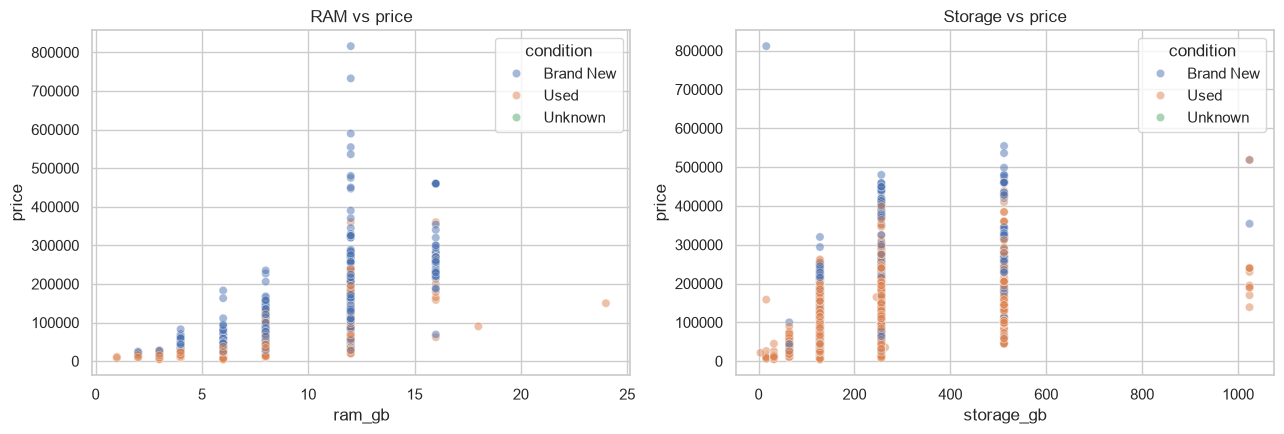

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="ram_gb", y="price", hue="condition", alpha=.5, ax=ax[0]); ax[0].set_title("RAM vs price")
sns.scatterplot(data=df, x="storage_gb", y="price", hue="condition", alpha=.5, ax=ax[1]); ax[1].set_title("Storage vs price")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "01_ram_storage_vs_price.png", dpi=150); plt.show()

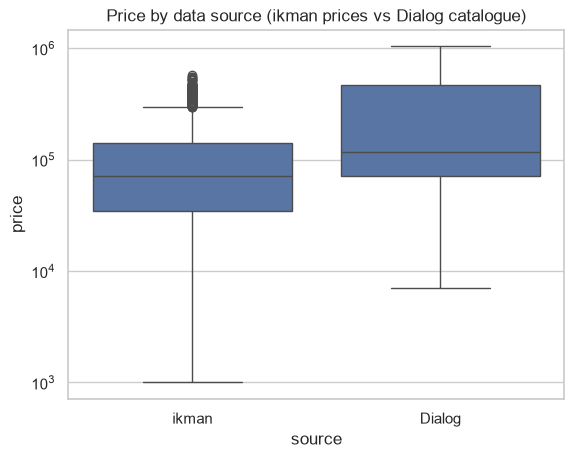

source
ikman     4398
Dialog      34
Name: count, dtype: int64
condition  Brand New   Unknown      Used
source                                  
Dialog    121,099.00       NaN 19,000.00
ikman      81,740.00 10,000.00 69,999.00


In [13]:
sns.boxplot(data=df, x="source", y="price"); plt.yscale("log"); plt.title("Price by data source (ikman prices vs Dialog catalogue)")
plt.savefig(config.PLOT_DIR / "01_source_vs_price.png", dpi=150); plt.show()
print(df["source"].value_counts())
print(df.groupby(["source", "condition"])["price"].median().unstack())

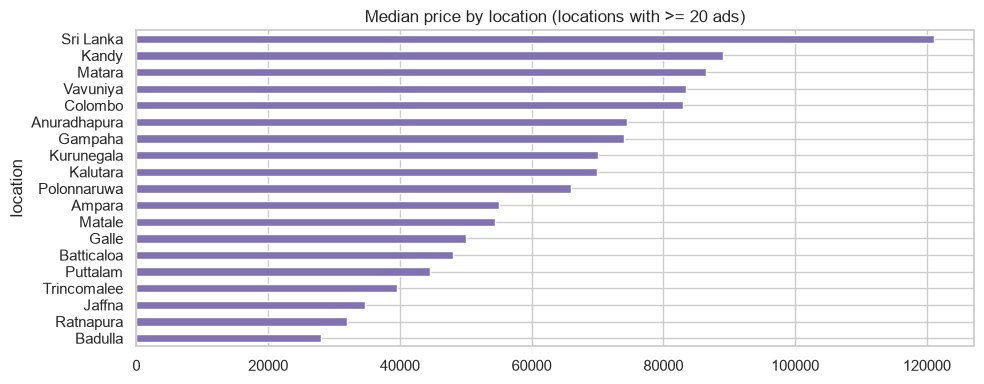

In [14]:
plt.figure(figsize=(10, 4))
loc_med = df.groupby("location")["price"].agg(["median", "size"]).query("size >= 20").sort_values("median")
loc_med["median"].plot(kind="barh", color="#8172B2"); plt.title("Median price by location (locations with >= 20 ads)")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "01_location_vs_price.png", dpi=150); plt.show()

## 7. Observations 

- **Price distribution:** Prices are right-skewed, with a mean of Rs. 102,000 and median of Rs. 72,500. Log transformation makes the distribution more balanced.
- **Brands:** Apple has the most listings (47%). Apple, Google and OnePlus have higher median prices, while Vivo, Xiaomi and Infinix are generally cheaper.
- **Condition:** Brand New phones have a higher median price than Used phones, but their price ranges overlap.
- **RAM and storage:** Higher RAM and storage generally mean higher prices, but brand and model also have a strong influence. Some extraction errors were identified.
- **ikman vs Dialog:** Dialog has very few listings (34) compared to ikman (4,398). Dialog's higher median price may be due to more flagship phones.
- **Location:** Median prices vary across locations, but some locations have very few listings, making location a weak pricing factor.
- **Data quality:** Six columns were completely empty. RAM and storage had missing and incorrectly extracted values. Also, 726 duplicate listings were removed, leaving 4,432 rows, and 27 suspicious prices were flagged for further checking.

---
# 02 - Data preprocessing and feature engineering
Turns the raw CSV into a clean dataset and a fixed **70 / 15 / 15 train / validation / test** split that every later notebook re-uses.



## 1. Clean the raw CSV
This section cleans the raw dataset by removing records with missing or invalid prices and duplicate listings. It identifies the data source, extracts RAM and storage information, and standardizes brand, condition, model name and location values. Suspicious prices are also flagged for further checking.

In [15]:
clean, report, splits = P.run_preprocessing()
report

27 suspicious prices flagged (kept unless drop_suspicious=True).


,step,rows_after
0,raw file,5158
1,drop missing price,5158
2,drop price <= 0,5158
3,drop duplicate listings,4432
4,final clean dataset,4432


In [16]:
clean.head(10)

,id,title,brand,model,condition,storage_gb,ram_gb,location,source,price,suspicious_price,ad_url
0,1,Apple iPhone 15 (Brand New),Apple,apple iphone 15,Brand New,NaN,NaN,Kandy,ikman,200000,False,https://ikman.lk/en/ad/apple-iphone-15-brand-n...
1,2,Samsung Galaxy A56 5G 8GB 256GB (Brand New),Samsung,samsung galaxy a56 5g,Brand New,256.00,8.00,Colombo,ikman,95989,False,https://ikman.lk/en/ad/samsung-galaxy-a56-5g-8...
2,3,Apple iPhone 14 128GB (Used),Apple,apple iphone 14,Used,128.00,NaN,Colombo,ikman,119999,False,https://ikman.lk/en/ad/apple-iphone-14-128gb-u...
3,4,Infinix Hot 60i 128GB 6GBRam Blue (Brand New),Infinix,infinix hot 60i,Brand New,128.00,6.00,Colombo,ikman,39990,False,https://ikman.lk/en/ad/infinix-hot-60i-128gb-6...
4,5,Apple iPhone 14 Pro (Used),Apple,apple iphone 14 pro,Used,NaN,NaN,Kurunegala,ikman,170000,False,https://ikman.lk/en/ad/apple-iphone-14-pro-use...
5,6,Apple iPhone 11 Pro 256GB (Used),Apple,apple iphone 11 pro,Used,256.00,NaN,Gampaha,ikman,89998,False,https://ikman.lk/en/ad/apple-iphone-11-pro-256...
6,7,Apple iPhone 15 Pro 256GB (Used),Apple,apple iphone 15 pro,Used,256.00,NaN,Kandy,ikman,224900,False,https://ikman.lk/en/ad/apple-iphone-15-pro-256...
7,8,Apple iPhone 15 Pro 5G- 4k cinematic (Used),Apple,apple iphone 15 pro 5g,Used,NaN,NaN,Colombo,ikman,198000,False,https://ikman.lk/en/ad/apple-iphone-15-pro-5g-...
8,9,Apple iPhone 12 mini 128GB Blue (Used),Apple,apple iphone 12 mini,Used,128.00,NaN,Colombo,ikman,69990,False,https://ikman.lk/en/ad/apple-iphone-12-mini-12...
9,10,Vivo Y93 6GB/ 128GB (Used),Vivo,vivo y93,Used,128.00,6.00,Colombo,ikman,8900,False,https://ikman.lk/en/ad/vivo-y93-6gb-128gb-used...


## 2. Review suspicious prices (flagged, **not** deleted automatically)
A price is flagged when it is below 40% or above 250% of the median of the same brand + model + condition group (groups of 5+), or below Rs. 3,000. Open the ad, decide whether it is a data error (remove it) or a real but unusual price (keep it).

In [17]:
sus = clean[clean["suspicious_price"]]
print(len(sus), "flagged rows")
sus[["id", "title", "model", "condition", "price", "source"]].head(30)

27 flagged rows


,id,title,model,condition,price,source
21,24,Nokia 106 (Used),nokia 106,Used,2500,ikman
93,99,Nokia 105 (Brand New),nokia 105,Brand New,2990,ikman
358,377,Xiaomi Redmi 15 128GB/256GB (Brand New),xiaomi redmi 15,Brand New,19100,ikman
395,420,Samsung Galaxy S24 Ultra (Brand New),samsung galaxy s24 ultra,Brand New,32360,ikman
489,520,Nokia 105 (Used),nokia 105,Used,1000,ikman
823,876,Corn Button Phone (Used),other corn button,Used,2500,ikman
916,976,Nokia 105 Dubai Series (Brand New),nokia 105 dubai series,Brand New,2990,ikman
1133,1206,Samsung Galaxy S21 Ultra (Used),samsung galaxy s21 ultra,Used,30000,ikman
1142,1215,Apple iPhone 14 Pro Max (Used),apple iphone 14 pro max,Used,70000,ikman
1720,1854,Apple iPhone 17 Pro Max 256GB (Brand New),apple iphone 17 pro max,Brand New,60000,ikman


in `src/config.py

## 3. Missing values in the model features
checks missing values in the features used for machine learning. Missing RAM and storage values are kept because they may still provide useful information. The model pipeline handles these missing values using median imputation and missing-value indicators.

In [18]:
clean[config.FEATURES + [config.TARGET]].isnull().sum()

brand            0
model            0
condition        0
location         0
source           0
storage_gb    1613
ram_gb        3313
price            0
dtype: int64

## 4. Features and target
| | |
|---|---|
| Target | `price` (LKR) |
| Categorical | `brand`, `model` (cleaned, brand + model name), `condition`, `location`, `source` |
| Numerical | `storage_gb`, `ram_gb` |
| Not used | `id`, `title`, `description`, `seller_name`, `ad_url`, `price_raw` (would leak the answer), `is_member`, `is_featured` |

## 5. Split sizes
divides the cleaned dataset into three separate subsets for training, validation and testing. It also compares the average prices and ikman data proportions in each subset.

In [19]:
for k, v in splits.items():
    print(f"{k:5s} {len(v):5d} rows | mean price {v['price'].mean():>10,.0f} | ikman share {(v['source']=='ikman').mean():.2f}")

train  3102 rows | mean price    102,561 | ikman share 0.99
val     665 rows | mean price    103,052 | ikman share 0.99
test    665 rows | mean price    101,315 | ikman share 0.99


### Leakage check: the same advert must not sit in both train and test

In [20]:
key = lambda d: d["title"].astype(str) + "|" + d["price"].astype(str) + "|" + d["location"].astype(str)
tr, va, te = splits["train"], splits["val"], splits["test"]
print("identical listings in train & test:", len(set(key(tr)) & set(key(te))))
print("identical listings in train & val :", len(set(key(tr)) & set(key(va))))

identical listings in train & test: 0
identical listings in train & val : 0


## 6. What the model pipeline does to the features
demonstrates how categorical and numerical features are converted into a format suitable for machine learning models. The preprocessing steps are fitted using training data only to prevent data leakage.

In [21]:
from src.features import build_preprocessor
X_tr, y_tr = P.xy(tr)
prep = build_preprocessor().fit(X_tr)
Xt = prep.transform(X_tr)
print("encoded feature matrix:", Xt.shape)
list(prep.get_feature_names_out())[:15]

encoded feature matrix: (3102, 234)


['num__storage_gb',
 'num__ram_gb',
 'num__missingindicator_storage_gb',
 'num__missingindicator_ram_gb',
 'cat__brand_Apple',
 'cat__brand_Google',
 'cat__brand_Honor',
 'cat__brand_Huawei',
 'cat__brand_Infinix',
 'cat__brand_Lg',
 'cat__brand_Nokia',
 'cat__brand_Nothing',
 'cat__brand_Oneplus',
 'cat__brand_Oppo',
 'cat__brand_Other']

## 7. Why a log-transformed target?
compares the distribution of original mobile phone prices with the log-transformed prices. Mobile phone prices can vary significantly, with a small number of expensive phones creating a right-skewed distribution.

Applying a logarithmic transformation helps reduce this skewness and makes the target distribution more balanced for model training.

In [22]:
print("skew of price      :", round(y_tr.skew(), 2))
print("skew of log(price) :", round(np.log1p(y_tr).skew(), 2))

skew of price      : 2.04
skew of log(price) : -0.4


---
# 03 - Baseline and Bagging (Random Forest, Extra Trees)
**Baseline - Ridge regression.** A simple linear model on the same encoded features. Every ensemble must beat it to justify its extra complexity.

**Bagging (bootstrap aggregating)** trains many trees independently and **averages** their predictions. Deep decision trees have low bias but high variance; averaging many de-correlated trees keeps the low bias and cuts the variance.
- **Random Forest:** each tree sees a bootstrap sample of the rows and a random subset of features at each split.
- **Extra Trees:** same idea, but split points are also chosen at random, which de-correlates the trees even more (faster, slightly more bias).



In [23]:
splits = P.load_splits()                   # same rows in every notebook (created in notebook 02)
X_tr, y_tr = P.xy(splits["train"])
X_va, y_va = P.xy(splits["val"])
print(len(X_tr), "train rows |", len(X_va), "validation rows")

3102 train rows | 665 validation rows


## 1. Baseline: Ridge regression
Ridge Regression is trained as the baseline model.
It makes predictions using the validation dataset. Its performance is measured using regression metrics such as MAE, RMSE, and R². The ensemble models are compared against this baseline.

In [24]:
ridge = M.make_ridge().fit(X_tr, y_tr)
p_ridge = ridge.predict(X_va)
pd.Series(regression_metrics(y_va, p_ridge), name="Ridge baseline (validation)").to_frame()

,Ridge baseline (validation)
MAE,"21,229.87"
RMSE,"42,128.03"
R2,0.81
MAPE_%,32.61
MedianAE,"9,608.32"


## 2. Tune on the training set
This section provides optional hyperparameter tuning for Random Forest and Extra Trees. It uses randomized search with 3-fold cross-validation on the training data. Tuning is disabled by default to reduce execution time.

Set `RUN_TUNING = True` to run a 3-fold randomised search (training data only). The best parameters are stored in `outputs/best_params.json` and picked up automatically by every notebook.

In [25]:
RUN_TUNING = False
if RUN_TUNING:
    for name in ["random_forest", "extra_trees"]:
        best, cv_mae, _ = M.tune(name, X_tr, y_tr, n_iter=12)
        print(name, "best params:", best, "| CV MAE:", round(cv_mae))
print("RF params in use:", {k: v for k, v in M.rf_regressor().get_params().items() if k in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]})

RF params in use: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 200}


## 3. Random Forest - train and evaluate on the validation set
Trains the Random Forest model and evaluates its predictions using the validation dataset. The scatter plot compares actual and predicted prices, while the residual histogram shows the prediction errors.

In [26]:
rf = M.make_random_forest()          # preprocessing + RandomForestRegressor, trained on log(price)
rf.fit(X_tr, y_tr)
pred = rf.predict(X_va)
pd.Series(regression_metrics(y_va, pred), name="Random Forest (validation)").to_frame()

,Random Forest (validation)
MAE,"17,139.68"
RMSE,"33,975.96"
R2,0.87
MAPE_%,29.43
MedianAE,"8,361.19"


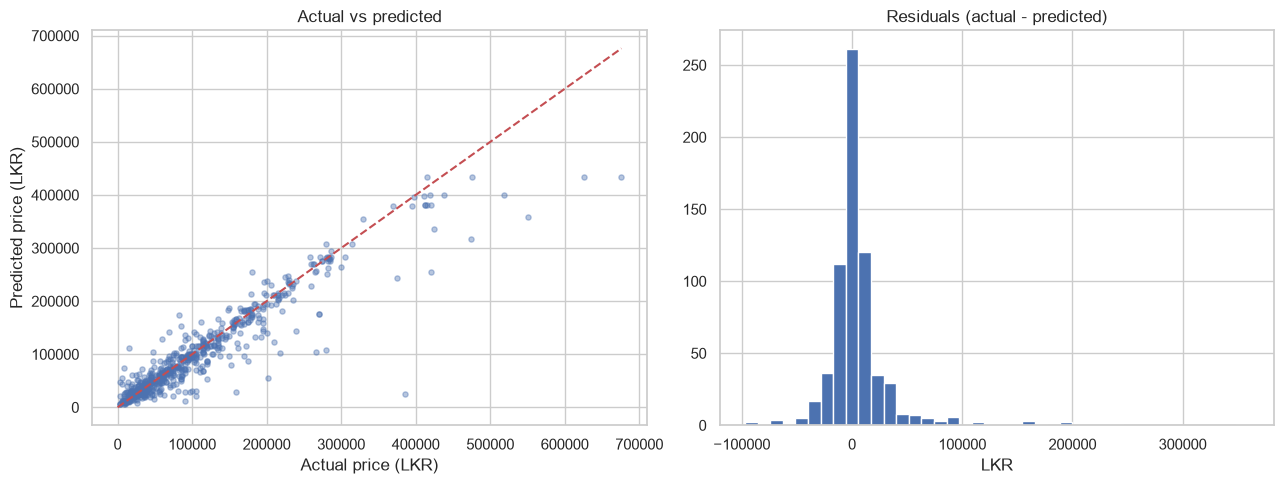

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_va, pred, alpha=.4, s=14); lim = [0, max(y_va.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual price (LKR)"); ax[0].set_ylabel("Predicted price (LKR)"); ax[0].set_title("Actual vs predicted")
ax[1].hist(y_va - pred, bins=40, color="#4C72B0"); ax[1].set_title("Residuals (actual - predicted)"); ax[1].set_xlabel("LKR")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "03_rf_actual_vs_pred.png", dpi=150); plt.show()

## 4. Extra Trees and the comparison with Ridge
 trains the Extra Trees model and compares it with Ridge Regression and Random Forest. The comparison table shows the validation performance of all three models using the same evaluation metrics.

In [28]:
et = M.make_extra_trees().fit(X_tr, y_tr)
p_et = et.predict(X_va)
pd.DataFrame({"Ridge baseline": regression_metrics(y_va, p_ridge), "Random Forest": regression_metrics(y_va, pred),
              "Extra Trees": regression_metrics(y_va, p_et)}).T

,MAE,RMSE,R2,MAPE_%,MedianAE
Ridge baseline,"21,229.87","42,128.03",0.81,32.61,"9,608.32"
Random Forest,"17,139.68","33,975.96",0.87,29.43,"8,361.19"
Extra Trees,"18,630.32","35,504.95",0.86,33.15,"9,842.23"


## 5. Why bagging works: error vs number of trees
 examines how the number of trees affects Random Forest performance. It calculates training and validation MAE for different numbers of trees and plots the results to observe changes in prediction error.

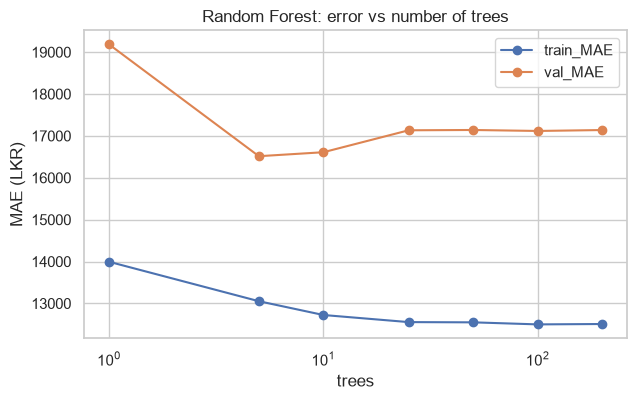

,trees,val_MAE,train_MAE
0,1,"19,184.50","13,994.25"
1,5,"16,515.13","13,052.73"
2,10,"16,609.76","12,723.49"
3,25,"17,133.71","12,553.91"
4,50,"17,140.98","12,548.24"
5,100,"17,117.66","12,499.25"
6,200,"17,139.68","12,508.32"


In [29]:
rows = []
for k in [1, 5, 10, 25, 50, 100, 200]:
    m = M.make_random_forest(n_estimators=k).fit(X_tr, y_tr)
    rows.append({"trees": k, "val_MAE": regression_metrics(y_va, m.predict(X_va))["MAE"],
                 "train_MAE": regression_metrics(y_tr, m.predict(X_tr))["MAE"]})
curve = pd.DataFrame(rows)
curve.plot(x="trees", y=["train_MAE", "val_MAE"], marker="o", figsize=(7, 4), logx=True)
plt.ylabel("MAE (LKR)"); plt.title("Random Forest: error vs number of trees")
plt.savefig(config.PLOT_DIR / "03_rf_trees_curve.png", dpi=150); plt.show()
curve

## 6. Which features matter?
 identifies the features that contribute most to the Random Forest model's predictions. It calculates grouped feature importance and displays the results as a bar chart.

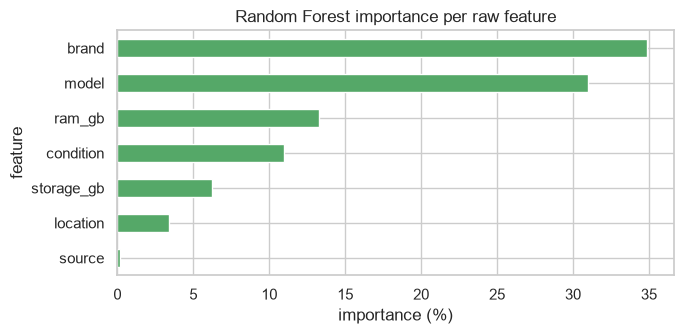

,feature,importance_%
0,brand,34.90
1,model,30.96
2,ram_gb,13.28
3,condition,11.00
4,storage_gb,6.25
5,location,3.42
6,source,0.18


In [30]:
from src.explain import grouped_importance
imp = grouped_importance(rf)
imp.sort_values("importance_%").plot.barh(x="feature", y="importance_%", legend=False, figsize=(7, 3.5), color="#55A868")
plt.xlabel("importance (%)"); plt.title("Random Forest importance per raw feature"); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "03_rf_feature_importance.png", dpi=150); plt.show()
imp

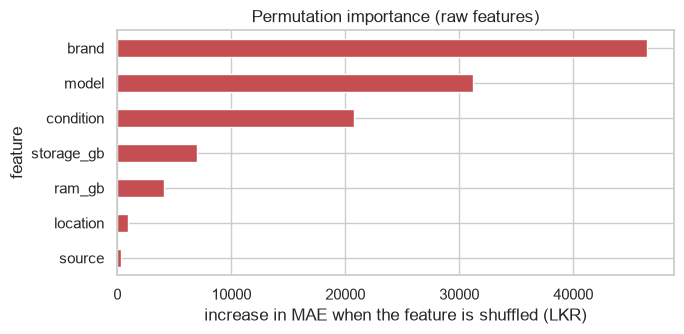

,feature,mae_increase,std
0,brand,"46,508.12","1,182.96"
1,model,"31,232.53",663.34
2,condition,"20,766.26","1,788.22"
5,storage_gb,"6,963.96",639.49
6,ram_gb,"4,108.63",302.34
3,location,947.18,315.36
4,source,295.44,8.14


In [31]:
pi = permutation_table(rf, X_va, y_va)
pi.sort_values("mae_increase").plot.barh(x="feature", y="mae_increase", legend=False, figsize=(7, 3.5), color="#C44E52")
plt.xlabel("increase in MAE when the feature is shuffled (LKR)"); plt.title("Permutation importance (raw features)")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "03_rf_permutation_importance.png", dpi=150); plt.show()
pi

## 7. Note

- **Baseline vs Random Forest:** Random Forest performs better than Ridge, reducing MAE by 19% and improving R² from 0.81 to 0.87.
- **Random Forest vs Extra Trees:** Random Forest performs better, with lower MAE and higher R².
- **Bagging:** Averaging multiple trees reduces prediction error by about 11% compared to a single tree. Performance becomes stable after around 25 trees.
- **Over-fitting:** Training MAE is lower than validation MAE, showing some over-fitting, but the gap remains stable.
- **Important features:** Brand (35%) and model (31%) are the most important features, followed by RAM, condition and storage. Source has very little impact. Permutation importance also confirms brand and model as the top features.

---
# 04 - Boosting: XGBoost, LightGBM, CatBoost
**Boosting** builds shallow trees *sequentially*; each new tree is fitted to the errors left by the trees before it, and its contribution is shrunk by a learning rate. Boosting mainly reduces **bias**; too many rounds can over-fit.

| | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| Tree growth | depth-wise (level by level) | leaf-wise (best leaf first), histogram based | symmetric ("oblivious") trees |
| Known for | regularisation, robust default | speed on large data | ordered boosting, native categorical handling, good defaults |




In [32]:
splits = P.load_splits()                   # same rows in every notebook (created in notebook 02)
X_tr, y_tr = P.xy(splits["train"])
X_va, y_va = P.xy(splits["val"])
print(len(X_tr), "train rows |", len(X_va), "validation rows")

3102 train rows | 665 validation rows


In [33]:
HAS_LGBM, HAS_CAT = M.has_lightgbm(), M.has_catboost()
print("LightGBM available:", HAS_LGBM, "| CatBoost available:", HAS_CAT, "(pip install lightgbm catboost)")

LightGBM available: True | CatBoost available: True (pip install lightgbm catboost)


## 1. Optional tuning (training set only)


In [34]:
RUN_TUNING = False
if RUN_TUNING:
    for name in ["xgboost"] + (["lightgbm"] if HAS_LGBM else []) + (["catboost"] if HAS_CAT else []):
        best, cv_mae, _ = M.tune(name, X_tr, y_tr, n_iter=10)
        print(name, best, "| CV MAE:", round(cv_mae))

## 2. Train the three boosters and compare (validation set)
trains the available boosting models and measures their training time. It evaluates their predictions on the validation dataset and compares their performance using regression metrics.

In [35]:
import time
boosters = {"XGBoost": M.make_xgboost}
if HAS_LGBM: boosters["LightGBM"] = M.make_lightgbm
if HAS_CAT:  boosters["CatBoost"] = M.make_catboost
fitted, rows = {}, []
for name, make in boosters.items():
    t = time.perf_counter(); m = make().fit(X_tr, y_tr); secs = time.perf_counter() - t
    fitted[name] = m
    rows.append({"Model": name, **regression_metrics(y_va, m.predict(X_va)), "train_time_s": secs})
boost_table = pd.DataFrame(rows).set_index("Model")
boost_table

,MAE,RMSE,R2,MAPE_%,MedianAE,train_time_s
Model,,,,,,
XGBoost,"24,286.86","42,934.85",0.80,37.18,"13,455.70",0.97
LightGBM,"21,887.53","40,909.24",0.82,38.51,"10,794.10",2.69
CatBoost,"24,380.32","43,230.72",0.80,37.06,"13,182.03",2.10


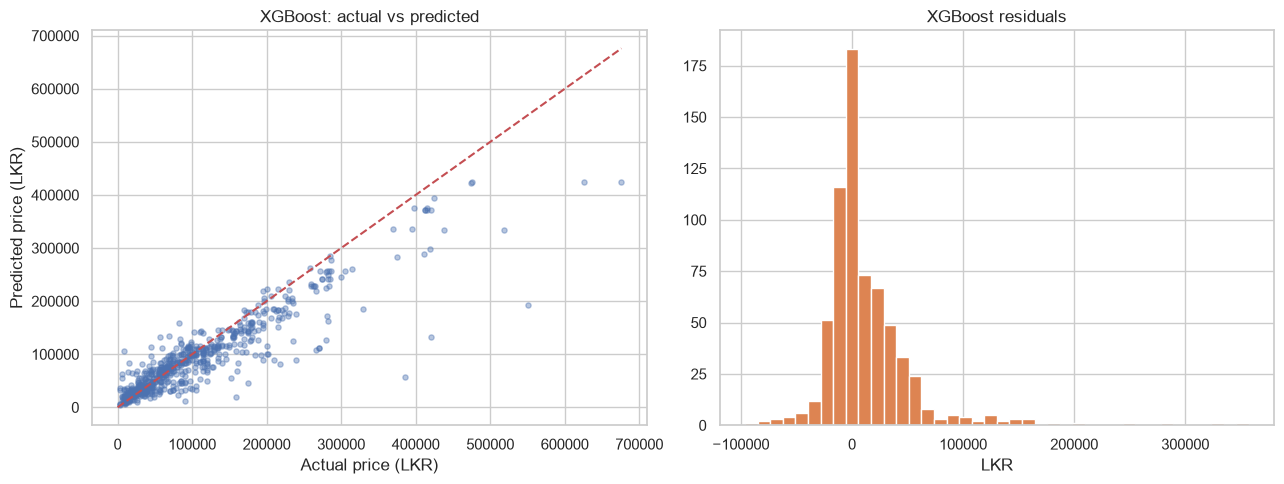

In [36]:
xgb = fitted["XGBoost"]; pred = xgb.predict(X_va)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_va, pred, alpha=.4, s=14); lim = [0, max(y_va.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual price (LKR)"); ax[0].set_ylabel("Predicted price (LKR)"); ax[0].set_title("XGBoost: actual vs predicted")
ax[1].hist(y_va - pred, bins=40, color="#DD8452"); ax[1].set_title("XGBoost residuals"); ax[1].set_xlabel("LKR")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "04_xgb_actual_vs_pred.png", dpi=150); plt.show()

## 3. Boosting rounds: training error keeps falling, validation error flattens
 examines how the number of boosting rounds affects XGBoost performance. It trains models with different numbers of rounds and compares their training and validation MAE using a line graph.

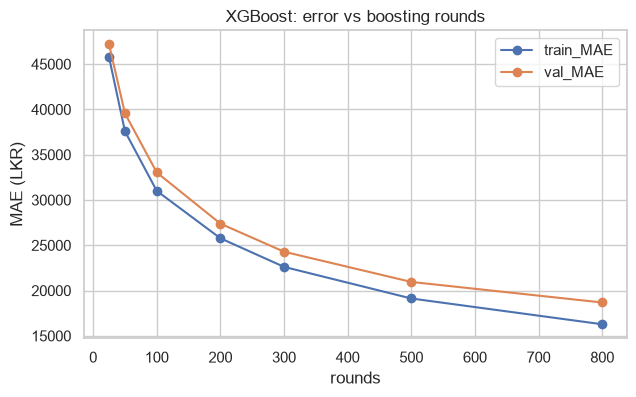

,rounds,train_MAE,val_MAE
0,25,"45,754.69","47,188.84"
1,50,"37,579.49","39,556.78"
2,100,"31,002.64","33,033.92"
3,200,"25,770.23","27,384.24"
4,300,"22,612.97","24,286.86"
5,500,"19,123.71","20,951.18"
6,800,"16,277.85","18,681.98"


In [37]:
rows = []
for k in [25, 50, 100, 200, 300, 500, 800]:
    m = M.make_xgboost(n_estimators=k).fit(X_tr, y_tr)
    rows.append({"rounds": k, "train_MAE": regression_metrics(y_tr, m.predict(X_tr))["MAE"],
                 "val_MAE": regression_metrics(y_va, m.predict(X_va))["MAE"]})
curve = pd.DataFrame(rows)
curve.plot(x="rounds", y=["train_MAE", "val_MAE"], marker="o", figsize=(7, 4))
plt.ylabel("MAE (LKR)"); plt.title("XGBoost: error vs boosting rounds")
plt.savefig(config.PLOT_DIR / "04_xgb_rounds_curve.png", dpi=150); plt.show()
curve

## 4. Feature importance of each booster
compares the feature importance of the available boosting models. It identifies which features contribute most to the predictions and displays the results in a comparison chart.

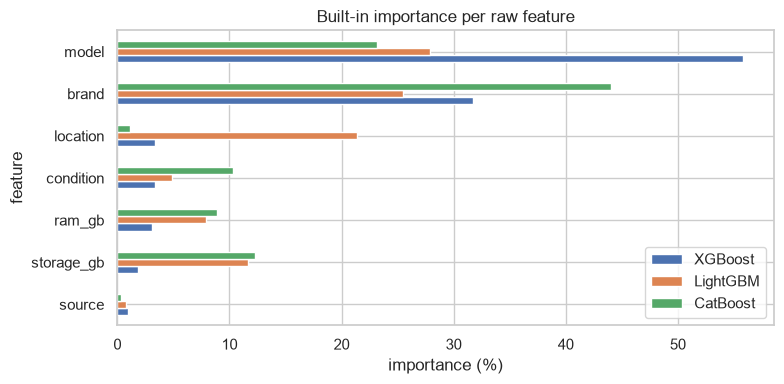

,XGBoost,LightGBM,CatBoost
feature,,,
model,55.78,27.87,23.12
brand,31.73,25.52,43.99
location,3.36,21.42,1.14
condition,3.32,4.88,10.35
ram_gb,3.08,7.89,8.84
storage_gb,1.81,11.68,12.27
source,0.91,0.75,0.28


In [38]:
from src.explain import grouped_importance
imps = pd.concat({n: grouped_importance(m).set_index("feature")["importance_%"] for n, m in fitted.items()}, axis=1).fillna(0)
imps.sort_values(imps.columns[0]).plot.barh(figsize=(8, 4)); plt.xlabel("importance (%)")
plt.title("Built-in importance per raw feature"); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "04_booster_importance.png", dpi=150); plt.show()
imps

## Notes

- **Best booster:** LightGBM performed best (MAE Rs. 21,888, R² 0.82), while XGBoost was the fastest to train.
- **Boosting vs Random Forest:** All boosters performed worse than Random Forest with default settings. However, XGBoost improved significantly with more rounds, showing that additional tuning could improve performance.
- **Over-fitting:** Training and validation errors are relatively close, suggesting the boosters are more under-fitted than over-fitted.
- **Feature importance:** Brand and model are the most important features for XGBoost and CatBoost. LightGBM distributes importance more evenly. Source has very little impact across all three models.


---
# 05 - Stacking
**Stacking** trains different base models and then a **meta-model** learns how to combine their predictions.
- Base models: Random Forest (bagging), XGBoost, LightGBM and CatBoost (boosting). LightGBM / CatBoost are used if installed.
- Meta-model: Ridge regression (cross-validated regularisation).
- `cv=5`: the meta-model is trained on **out-of-fold** predictions of the base models, so it never sees predictions the base models made on their own training rows.


In [39]:
splits = P.load_splits()                   # same rows in every notebook (created in notebook 02)
X_tr, y_tr = P.xy(splits["train"])
X_va, y_va = P.xy(splits["val"])
print(len(X_tr), "train rows |", len(X_va), "validation rows")

3102 train rows | 665 validation rows


In [40]:
print("base models in the stack:", M.stacking_base_names())
singles = {"random_forest": M.make_random_forest, "xgboost": M.make_xgboost,
           "lightgbm": M.make_lightgbm, "catboost": M.make_catboost}
base_preds = {n: singles[n]().fit(X_tr, y_tr).predict(X_va) for n in M.stacking_base_names()}
errors = pd.DataFrame({n: y_va.values - p for n, p in base_preds.items()})
print("correlation of the base models' errors:")
errors.corr().round(3)

base models in the stack: ['random_forest', 'xgboost', 'lightgbm', 'catboost']
correlation of the base models' errors:


,random_forest,xgboost,lightgbm,catboost
random_forest,1.00,0.81,0.84,0.79
xgboost,0.81,1.00,0.83,0.98
lightgbm,0.84,0.83,1.00,0.84
catboost,0.79,0.98,0.84,1.00


### Training the Stacking Model

The stacking model is trained using the training dataset. The base models generate predictions, and the Ridge meta-model learns how to combine them. The model then predicts phone prices using the validation dataset.

The meta-model weights show how the different base models contribute to the final prediction. The alpha value represents the regularisation strength selected for Ridge Regression.

In [41]:
stack = M.make_stacking()
stack.fit(X_tr, y_tr)
p_stack = stack.predict(X_va)
meta = stack.regressor_.final_estimator_
print("meta-model weights (log-price space):")
print(pd.Series(meta.coef_, index=M.stacking_base_names()).round(3).to_string())
print("intercept = %.3f, chosen alpha = %.3g" % (meta.intercept_, meta.alpha_))

meta-model weights (log-price space):
random_forest   0.62
xgboost         0.04
lightgbm        0.10
catboost        0.27
intercept = -0.334, chosen alpha = 4.33


### Model Performance Comparison

The validation performance of the individual base models is compared with a simple average and the stacking model. MAE, RMSE and R² are used to evaluate their performance. Lower MAE and RMSE values indicate better predictions, while a higher R² indicates a better model fit.

In [42]:
p_avg = np.mean(list(base_preds.values()), axis=0)
rows = {n: regression_metrics(y_va, p) for n, p in base_preds.items()}
rows["Simple average"] = regression_metrics(y_va, p_avg)
rows["Stacking (Ridge meta)"] = regression_metrics(y_va, p_stack)
table = pd.DataFrame(rows).T
table

,MAE,RMSE,R2,MAPE_%,MedianAE
random_forest,"17,139.68","33,975.96",0.87,29.43,"8,361.19"
xgboost,"24,286.86","42,934.85",0.80,37.18,"13,455.70"
lightgbm,"21,887.53","40,909.24",0.82,38.51,"10,794.10"
catboost,"24,380.32","43,230.72",0.80,37.06,"13,182.03"
Simple average,"20,458.15","38,026.37",0.84,34.09,"10,791.18"
Stacking (Ridge meta),"17,898.16","34,494.32",0.87,30.43,"9,026.39"


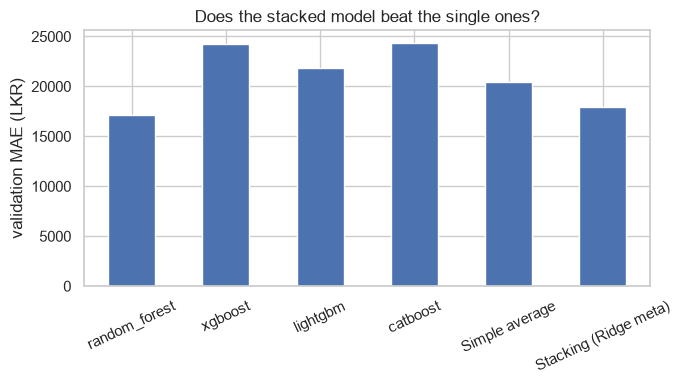

In [43]:
fig, ax = plt.subplots(figsize=(7, 4))
table["MAE"].plot.bar(ax=ax, color="#4C72B0"); ax.set_ylabel("validation MAE (LKR)")
ax.set_title("Does the stacked model beat the single ones?"); plt.xticks(rotation=25); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "05_stacking_vs_base.png", dpi=150); plt.show()

## Notes
- **Stacking performance:** Stacking achieved a validation MAE of Rs. 17,898, which was 4% worse than Random Forest (Rs. 17,140). However, it performed better than the boosters and simple averaging.
- **Why stacking didn't perform better:** Base models made similar predictions, so stacking had little new information to combine. XGBoost and CatBoost had a high error correlation of 0.98.
- **Meta-model weights:** Ridge gave the highest weight to Random Forest (0.62), showing that it relied mostly on the strongest base model. Limited training data and weaker boosters also affected stacking performance.

---
# 06 - Hybridisation: Random Forest + Artificial Neural Network
Hybridisation combines predictions from two different machine learning models. In this notebook, Random Forest and Artificial Neural Network (ANN) are combined for mobile phone price prediction. A weight is selected using validation MAE to determine how much each model contributes to the final prediction. Unlike stacking, this approach does not use a separate trained meta-model.

`P_hybrid = w * P_RF + (1 - w) * P_ANN`

The weight `w` is chosen on the **validation** set. This differs from stacking: there is no trained meta-model, only one weight picked by validation MAE.
The ANN is an `MLPRegressor` (64 -> 32 hidden units, ReLU, Adam, early stopping) on one-hot encoded, scaled inputs; the target is log-price standardised to mean 0, variance 1.


In [44]:
splits = P.load_splits()                   # same rows in every notebook (created in notebook 02)
X_tr, y_tr = P.xy(splits["train"])
X_va, y_va = P.xy(splits["val"])
print(len(X_tr), "train rows |", len(X_va), "validation rows")

3102 train rows | 665 validation rows


In [45]:
hyb = M.make_hybrid().fit(X_tr, y_tr)
p_rf, p_ann = hyb.predict_components(X_va)
print("RF  alone:", {k: round(v, 3) for k, v in regression_metrics(y_va, p_rf).items()})
print("ANN alone:", {k: round(v, 3) for k, v in regression_metrics(y_va, p_ann).items()})

RF  alone: {'MAE': 17139.677, 'RMSE': 33975.963, 'R2': 0.874, 'MAPE_%': 29.426, 'MedianAE': 8361.186}
ANN alone: {'MAE': 19185.063, 'RMSE': 37191.225, 'R2': 0.849, 'MAPE_%': 32.118, 'MedianAE': 9439.946}


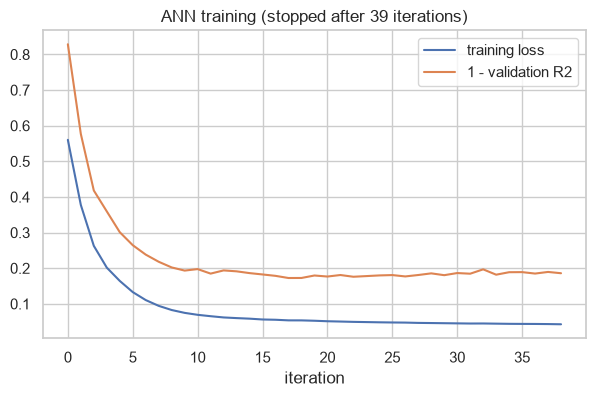

In [46]:
mlp = hyb.ann_.regressor_.named_steps["model"]
plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_, label="training loss")
if getattr(mlp, "validation_scores_", None) is not None:
    plt.plot(1 - np.array(mlp.validation_scores_), label="1 - validation R2")
plt.xlabel("iteration"); plt.legend(); plt.title(f"ANN training (stopped after {mlp.n_iter_} iterations)")
plt.savefig(config.PLOT_DIR / "06_ann_training_curve.png", dpi=150); plt.show()

## Weight experiment (validation set)

In [47]:
rows = []
for w in np.round(np.arange(0.1, 1.0, 0.1), 1):
    m = regression_metrics(y_va, w * p_rf + (1 - w) * p_ann)
    rows.append({"RF weight": w, "ANN weight": round(1 - w, 1), "validation MAE": m["MAE"], "validation RMSE": m["RMSE"], "validation R2": m["R2"]})
wt = pd.DataFrame(rows)
best_w = float(wt.sort_values("validation MAE").iloc[0]["RF weight"])
print("best RF weight:", best_w)
wt

best RF weight: 0.8


,RF weight,ANN weight,validation MAE,validation RMSE,validation R2
0,0.10,0.90,"18,657.96","36,261.43",0.86
1,0.20,0.80,"18,193.92","35,449.79",0.86
2,0.30,0.70,"17,786.04","34,764.58",0.87
3,0.40,0.60,"17,443.44","34,213.39",0.87
4,0.50,0.50,"17,177.04","33,802.78",0.88
5,0.60,0.40,"16,994.86","33,537.91",0.88
6,0.70,0.30,"16,887.84","33,422.26",0.88
7,0.80,0.20,"16,873.99","33,457.36",0.88
8,0.90,0.10,"16,928.11","33,642.75",0.88


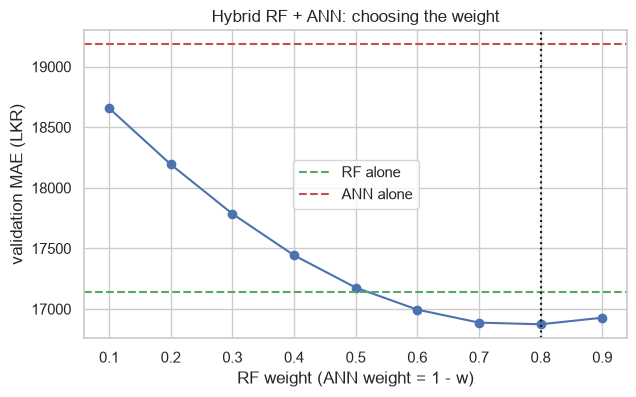

In [48]:
plt.figure(figsize=(7, 4))
plt.plot(wt["RF weight"], wt["validation MAE"], marker="o")
plt.axhline(regression_metrics(y_va, p_rf)["MAE"], ls="--", c="g", label="RF alone")
plt.axhline(regression_metrics(y_va, p_ann)["MAE"], ls="--", c="r", label="ANN alone")
plt.axvline(best_w, ls=":", c="k"); plt.xlabel("RF weight (ANN weight = 1 - w)"); plt.ylabel("validation MAE (LKR)")
plt.legend(); plt.title("Hybrid RF + ANN: choosing the weight")
plt.savefig(config.PLOT_DIR / "06_hybrid_weights.png", dpi=150); plt.show()

In [49]:
p_h = best_w * p_rf + (1 - best_w) * p_ann
pd.Series(regression_metrics(y_va, p_h), name=f"Hybrid w_RF={best_w} (validation)").to_frame()

,Hybrid w_RF=0.8 (validation)
MAE,"16,873.99"
RMSE,"33,457.36"
R2,0.88
MAPE_%,29.37
MedianAE,"8,017.64"


## Notes

- **Hybrid performance:** The hybrid model (80% RF + 20% ANN) performed best, achieving an MAE of Rs. 16,874 and R² of 0.88, slightly better than both RF and ANN alone.
- **Why hybrid works:** Random Forest and ANN learn patterns differently. Combining their predictions helps reduce errors. The higher RF weight reflects its stronger individual performance.
- **Weight sensitivity:** Weights between 0.7 and 0.9 produced similar results, showing that performance is not highly sensitive to the exact weight.

---
# 07 - Final model comparison (all 8 models)
**Protocol**
1. Every model is fitted on the **training** set and scored on the **validation** set -> used to pick the best model and the hybrid weight.
2. Every model is **refitted on train + validation** and scored **once** on the untouched **test** set -> the numbers reported in the report and dashboard. Training time of this refit and a **5-fold cross-validation** on train + validation are recorded too.

The code for this protocol is `src/train_models.py` (run below). It saves `models/*.pkl`, `outputs/model_comparison.csv` and the supporting metric files used by the dashboard.


## 1. Run the full protocol
The full training pipeline is executed using the reusable training module. It trains and evaluates all models according to the defined protocol. Five-fold cross-validation is enabled to provide additional information about model performance. The trained models and evaluation results are saved for later use in the dashboard and report.

In [50]:
from src import train_models
test_df = train_models.main(cv=True)

train/val/test = 3102/665/665 rows
models: ridge, random_forest, extra_trees, xgboost, lightgbm, catboost, stacking, hybrid
hybrid: best RF weight on validation = 0.8
  validation Ridge Regression (baseline): MAE=21,230  (3.5s)
  validation Random Forest (Bagging): MAE=17,140  (1.0s)
  validation Extra Trees (Bagging): MAE=18,630  (1.2s)
  validation XGBoost (Boosting): MAE=24,287  (0.6s)
  validation LightGBM (Boosting): MAE=21,888  (2.0s)
  validation CatBoost (Boosting): MAE=24,380  (1.8s)
  validation Stacking (Ridge meta-model): MAE=17,898  (28.4s)
  validation Hybrid (RF + ANN): MAE=16,874  (1.9s)
  test Ridge Regression (baseline): MAE=20,211 R2=0.787 time=1.5s CV_MAE=21,411±1,810
  test Random Forest (Bagging): MAE=16,347 R2=0.850 time=1.0s CV_MAE=17,649±843
  test Extra Trees (Bagging): MAE=17,816 R2=0.844 time=1.4s CV_MAE=19,025±1,099
  test XGBoost (Boosting): MAE=23,757 R2=0.806 time=0.7s CV_MAE=24,457±1,739
  test LightGBM (Boosting): MAE=20,021 R2=0.840 time=2.2s CV_MAE=2

In [51]:
from src.evaluate import mark_best
val_df = pd.read_csv(config.OUT_DIR / "validation_comparison.csv")
test_df = pd.read_csv(config.OUT_DIR / "model_comparison.csv")
gap = pd.read_csv(config.METRIC_DIR / "overfitting_gap.csv")
best_val = (config.OUT_DIR / "best_model.txt").read_text()
print("VALIDATION (used to choose the model)"); display(val_df) if "display" in globals() else print(val_df)
print("TEST (final result)  - trophy = lowest test MAE, tick = chosen on validation")
final_table = mark_best(test_df, best_val)
display(final_table) if "display" in globals() else print(final_table)

VALIDATION (used to choose the model)
                         Model       MAE      RMSE   R2  MAPE_%  MedianAE  \
0  Ridge Regression (baseline) 21,229.87 42,128.03 0.81   32.61  9,608.32   
1      Random Forest (Bagging) 17,139.68 33,975.96 0.87   29.43  8,361.19   
2        Extra Trees (Bagging) 18,630.32 35,504.95 0.86   33.15  9,842.23   
3           XGBoost (Boosting) 24,286.86 42,934.85 0.80   37.18 13,455.70   
4          LightGBM (Boosting) 21,887.53 40,909.24 0.82   38.51 10,794.10   
5          CatBoost (Boosting) 24,380.32 43,230.72 0.80   37.06 13,182.03   
6  Stacking (Ridge meta-model) 17,898.16 34,494.32 0.87   30.43  9,026.39   
7            Hybrid (RF + ANN) 16,873.99 33,457.36 0.88   29.37  8,017.64   

   Train_time_s  
0          3.55  
1          0.96  
2          1.24  
3          0.60  
4          2.00  
5          1.76  
6         28.41  
7          1.92  
TEST (final result)  - trophy = lowest test MAE, tick = chosen on validation
                             

## 2. Metric comparison charts (test set)
compares the eight models using six evaluation measures: MAE, RMSE, R², MAPE, training time and cross-validation MAE. The charts help identify the models with better prediction accuracy and training efficiency. Lower MAE, RMSE and MAPE values are preferred, while higher R² is better.

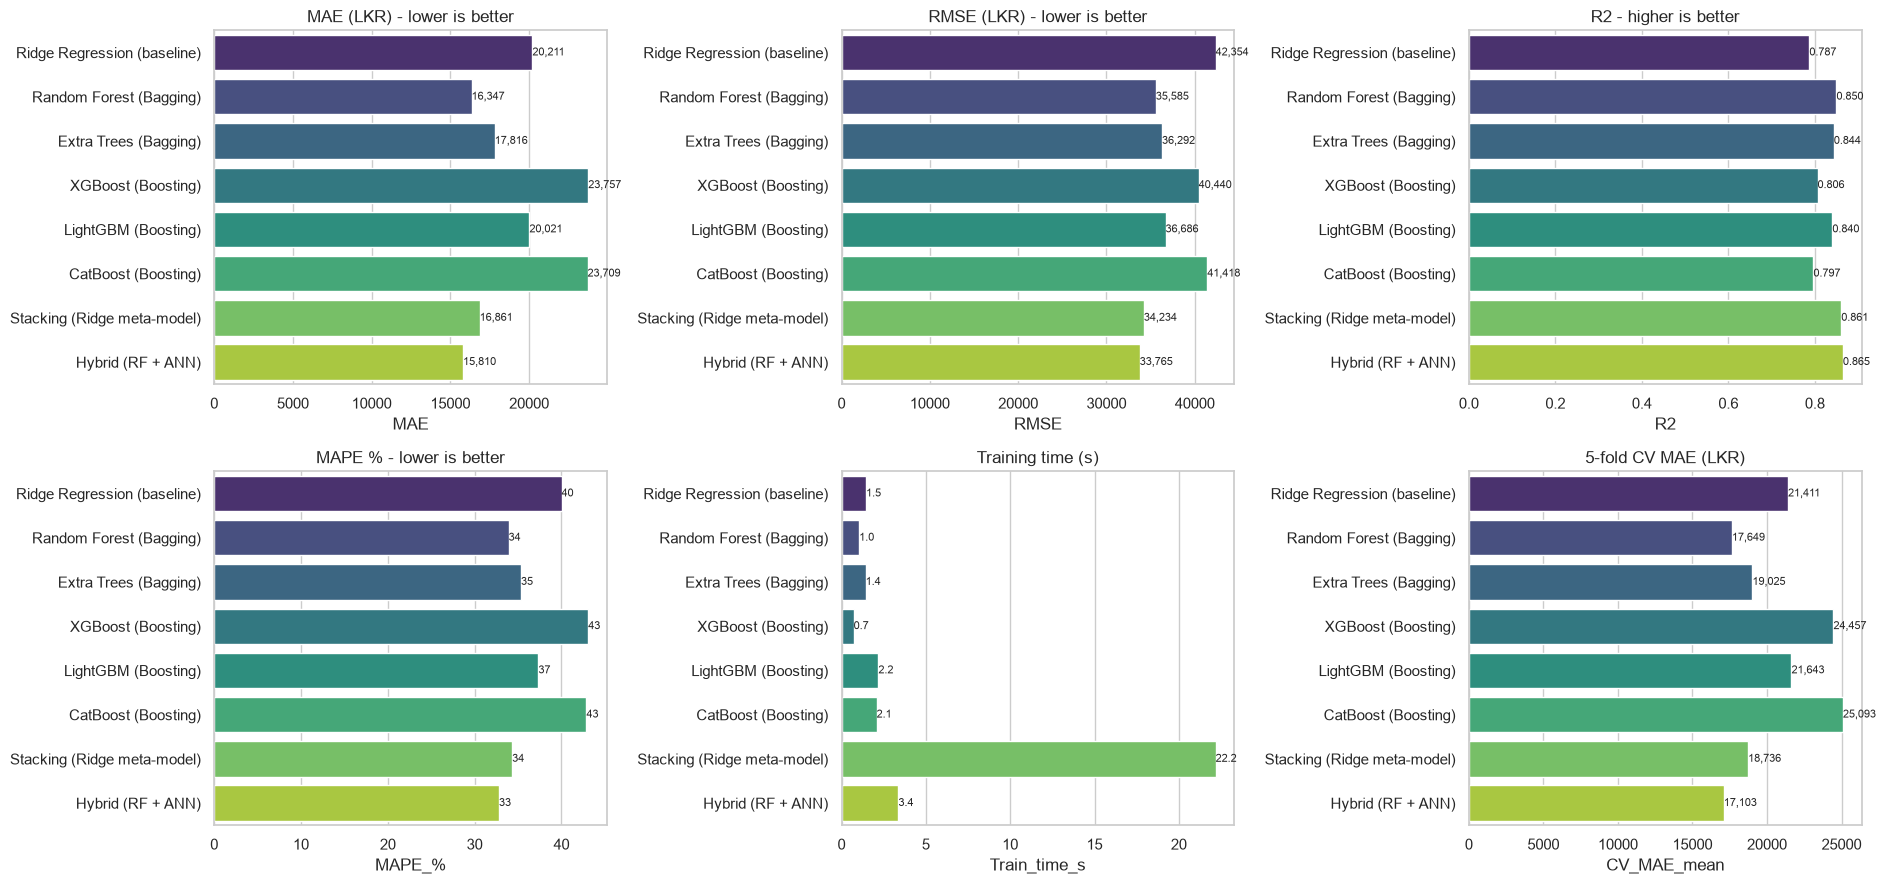

In [52]:
metrics = [("MAE", "MAE (LKR) - lower is better"), ("RMSE", "RMSE (LKR) - lower is better"), ("R2", "R2 - higher is better"),
           ("MAPE_%", "MAPE % - lower is better"), ("Train_time_s", "Training time (s)"), ("CV_MAE_mean", "5-fold CV MAE (LKR)")]
metrics = [m for m in metrics if m[0] in test_df.columns]
fig, ax = plt.subplots(2, 3, figsize=(19, 9))
for a, (col, title) in zip(ax.ravel(), metrics):
    sns.barplot(data=test_df, x=col, y="Model", ax=a, palette="viridis")
    a.set_title(title); a.set_ylabel("")
    for p in a.patches:
        w = p.get_width(); a.annotate(f"{w:,.3f}" if col == "R2" else f"{w:,.1f}" if col == "Train_time_s" else f"{w:,.0f}",
                                       (w, p.get_y() + p.get_height() / 2), ha="left", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "07_metric_comparison.png", dpi=150); plt.show()

## 3. Actual vs predicted and residuals (all models)

Actual and predicted prices are compared for all eight models using scatter plots. Predictions closer to the reference line indicate better accuracy. Residual distributions are also examined to understand whether models tend to overpredict or underpredict phone prices.

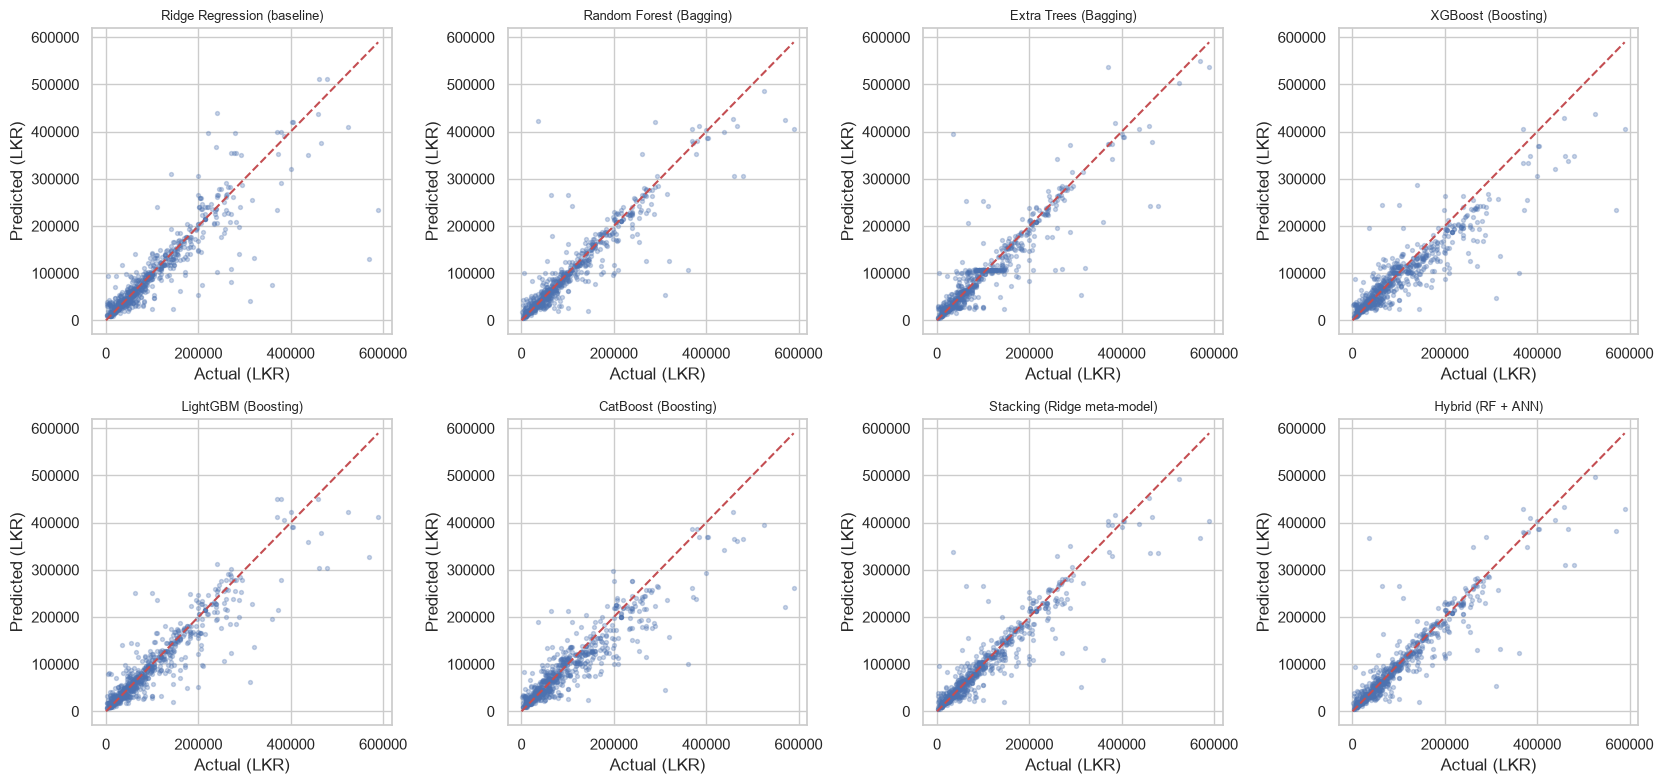

In [53]:
preds = pd.read_csv(config.OUT_DIR / "test_predictions.csv")
models_ = list(test_df["Model"])
ncols = 4; nrows = int(np.ceil(len(models_) / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4 * nrows))
for a, m in zip(ax.ravel(), models_):
    a.scatter(preds["price"], preds[m], alpha=.3, s=8); lim = [0, preds[["price", m]].max().max()]
    a.plot(lim, lim, "r--"); a.set_title(m, fontsize=9); a.set_xlabel("Actual (LKR)"); a.set_ylabel("Predicted (LKR)")
for a in ax.ravel()[len(models_):]: a.axis("off")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "07_actual_vs_predicted.png", dpi=150); plt.show()

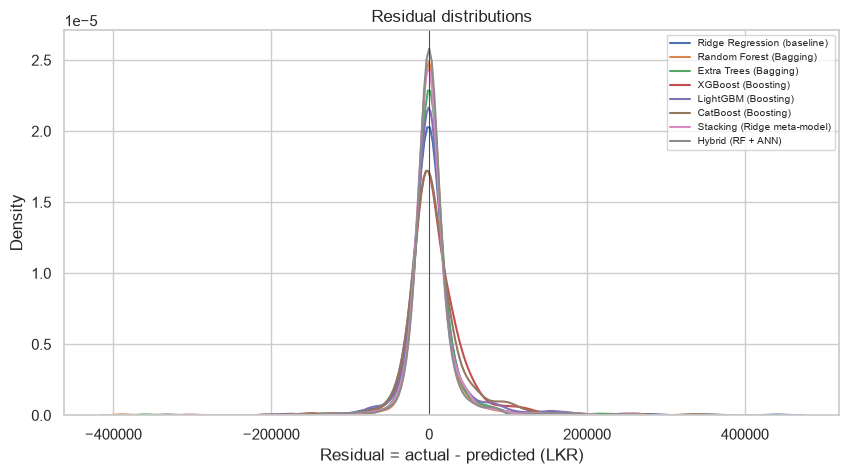

In [54]:
plt.figure(figsize=(10, 5))
for m in models_:
    sns.kdeplot(preds["price"] - preds[m], label=m)
plt.axvline(0, c="k", lw=.5); plt.xlabel("Residual = actual - predicted (LKR)"); plt.legend(fontsize=7); plt.title("Residual distributions")
plt.savefig(config.PLOT_DIR / "07_residuals.png", dpi=150); plt.show()

## 4. Where does each model make its errors? 
analyses model errors across different data sources and phone conditions. It helps identify whether models perform differently for each group. However, the Dialog dataset contains fewer records than ikman, so its results should be interpreted carefully because of the smaller sample size.

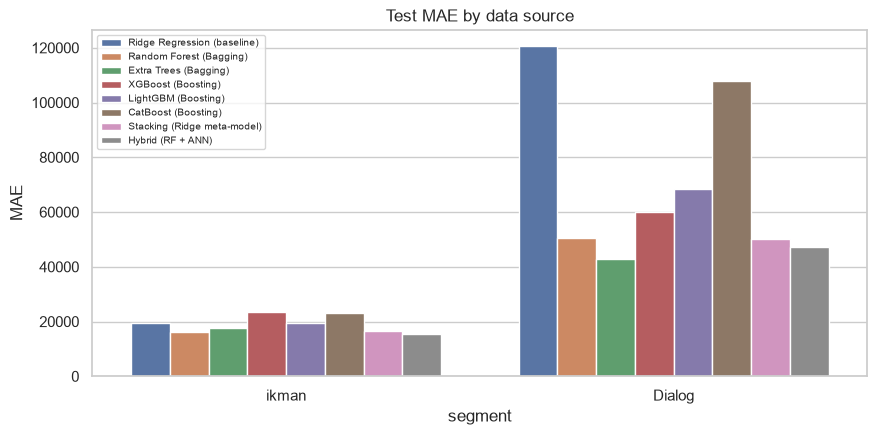

segment,Dialog,ikman
Model,,
CatBoost (Boosting),"107,900.24","22,942.94"
Extra Trees (Bagging),"43,015.55","17,586.54"
Hybrid (RF + ANN),"47,073.44","15,524.97"
LightGBM (Boosting),"68,502.47","19,579.43"
Random Forest (Bagging),"50,636.95","16,034.57"
Ridge Regression (baseline),"120,539.97","19,297.04"
Stacking (Ridge meta-model),"50,248.45","16,557.09"
XGBoost (Boosting),"59,997.96","23,427.03"


In [55]:
seg = pd.read_csv(config.METRIC_DIR / "error_by_segment.csv")
seg_src = seg[seg["segment_by"] == "source"]
plt.figure(figsize=(10, 4.5))
sns.barplot(data=seg_src, x="segment", y="MAE", hue="Model"); plt.title("Test MAE by data source"); plt.legend(fontsize=7)
plt.savefig(config.PLOT_DIR / "07_mae_by_source.png", dpi=150); plt.show()
seg_src.pivot(index="Model", columns="segment", values="MAE")

In [56]:
seg[seg["segment_by"] == "condition"].pivot(index="Model", columns="segment", values="MAE")

segment,Brand New,Used
Model,,
CatBoost (Boosting),"33,066.39","20,419.34"
Extra Trees (Bagging),"22,237.75","16,261.17"
Hybrid (RF + ANN),"22,085.34","13,602.91"
LightGBM (Boosting),"32,299.25","15,703.43"
Random Forest (Bagging),"23,329.01","13,891.63"
Ridge Regression (baseline),"30,315.37","16,657.38"
Stacking (Ridge meta-model),"24,017.59","14,344.66"
XGBoost (Boosting),"32,202.63","20,787.28"


In [57]:
print(seg_src.groupby("segment")["rows"].first())

segment
Dialog      6
ikman     659
Name: rows, dtype: int64


Dialog rows are far fewer than ikman rows, so Dialog-specific errors are based on a small sample.

## 5. Over-fitting check: train vs test R2
Training and test R² values are compared to identify possible overfitting. A large difference between these values may indicate that a model does not generalise well to unseen data. Cross-validation results are also considered to understand the consistency of model performance.

In [58]:
gap

,Model,R2_train,R2_test,R2_gap,MAE_train,MAE_test
0,Ridge Regression (baseline),0.80,0.79,0.01,"18,690.25","20,210.51"
1,Random Forest (Bagging),0.90,0.85,0.05,"12,057.56","16,346.77"
2,Extra Trees (Bagging),0.91,0.84,0.07,"11,920.61","17,815.98"
3,XGBoost (Boosting),0.82,0.81,0.01,"22,746.43","23,756.99"
4,LightGBM (Boosting),0.84,0.84,-0.00,"18,360.46","20,020.84"
5,CatBoost (Boosting),0.79,0.80,-0.00,"23,354.49","23,709.47"
6,Stacking (Ridge meta-model),0.89,0.86,0.03,"13,695.04","16,861.08"
7,Hybrid (RF + ANN),0.91,0.86,0.04,"11,690.97","15,809.62"


## 6. Feature importance
Feature importance is used to understand which input features contribute to model predictions. Permutation importance measures how much the test MAE increases when a feature is shuffled. A larger increase indicates that the feature has a stronger effect on the model's predictive performance.

In [59]:
imp = pd.read_csv(config.METRIC_DIR / "feature_importance.csv")
imp.pivot(index="feature", columns="Model", values="importance_%").round(1)

Model,CatBoost (Boosting),Extra Trees (Bagging),LightGBM (Boosting),Random Forest (Bagging),XGBoost (Boosting)
feature,,,,,
brand,44.60,32.40,23.60,34.80,31.30
condition,10.20,11.70,4.70,9.90,4.60
location,1.10,3.10,20.90,3.60,2.70
model,23.40,33.50,31.40,31.90,56.90
ram_gb,8.10,8.40,7.40,13.50,2.30
source,0.30,0.40,0.80,0.20,0.80
storage_gb,12.30,10.40,11.10,6.00,1.40


permutation importance of the validation-chosen model: Hybrid (RF + ANN)


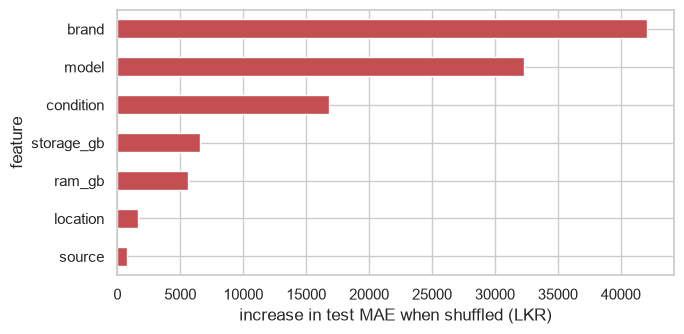

In [60]:
pi = pd.read_csv(config.METRIC_DIR / "permutation_importance_best.csv")
print("permutation importance of the validation-chosen model:", best_val)
pi.sort_values("mae_increase").plot.barh(x="feature", y="mae_increase", legend=False, figsize=(7, 3.5), color="#C44E52")
plt.xlabel("increase in test MAE when shuffled (LKR)"); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "07_permutation_importance.png", dpi=150); plt.show()

## 7. Hybrid weight experiment (validation)
The hybrid weight search results are loaded to review the different Random Forest and ANN weight combinations. The selected combination is based on the lowest validation MAE, not the test results.

In [61]:
pd.read_csv(config.METRIC_DIR / "hybrid_weight_search.csv")

,rf_weight,ann_weight,val_MAE,val_RMSE,val_R2
0,0.10,0.90,"18,657.96","36,261.43",0.86
1,0.20,0.80,"18,193.92","35,449.79",0.86
2,0.30,0.70,"17,786.04","34,764.58",0.87
3,0.40,0.60,"17,443.44","34,213.39",0.87
4,0.50,0.50,"17,177.04","33,802.78",0.88
5,0.60,0.40,"16,994.86","33,537.91",0.88
6,0.70,0.30,"16,887.84","33,422.26",0.88
7,0.80,0.20,"16,873.99","33,457.36",0.88
8,0.90,0.10,"16,928.11","33,642.75",0.88


## 8. Key findings (computed from the results)

In [62]:
from src.evaluate import key_findings
for line in key_findings(test_df, val_df, gap):
    print("-", line)

- Best model on the untouched test set: **Hybrid (RF + ANN)** (MAE Rs. 15,810, RMSE Rs. 33,765, R² 0.865).
- Weakest model: **XGBoost (Boosting)** (MAE Rs. 23,757); the best model's MAE is 33.5% lower.
- The best ensemble cuts the MAE of the Ridge baseline by 21.8%.
- Random Forest vs gradient boosting: best booster is **LightGBM (Boosting)** (MAE 22.5% higher than Random Forest); training time RF 1.0s vs 2.2s.
- Stacking vs its best single model: MAE did not improve by 3.1%.
- Hybrid RF + ANN vs Random Forest alone: MAE 3.3% lower.
- Largest train-to-test R² gap (a sign of over-fitting): **Extra Trees (Bagging)** (0.069).


## 9. Interpretation

- **Best model:** Hybrid (RF + ANN) achieved the lowest test MAE (Rs. 15,810) and R² of 0.865, improving MAE by 22% over Ridge.
- **Random Forest vs Boosting:** Random Forest outperformed all three boosting models, although further tuning may improve boosting performance.
- **Stacking and Hybrid:** Hybrid performed slightly better than Random Forest. Stacking did not improve MAE because the base models made similar errors.
- **Over-fitting:** Random Forest and Hybrid showed relatively small training-test gaps. Some boosting models were under-fitted rather than over-fitted.
- **Cost vs Accuracy:** Hybrid achieved the best accuracy in 6.5 seconds, while Random Forest was almost equally accurate and much faster. Stacking took 52 seconds without improving MAE.
- **Model weaknesses:** Predictions were less accurate for Brand New phones. Dialog results were unreliable due to the very small test sample.
- **Limitations:** The dataset contains asking prices rather than actual selling prices, missing RAM values, mixed data sources and some potentially incorrect prices. Results may change with further tuning and newer data.

---
# 08 - Innovation: the Fair Price Checker
Compares the advertised phone price with the price predicted by the selected machine learning model. It classifies advertisements as Good Deal, Fair Price or Overpriced based on the percentage difference. This feature helps buyers identify potentially attractive prices and helps sellers understand competitive pricing.

`difference = asking / predicted - 1`  ->  **Good deal** (below -tolerance) | **Fair price** (within +-tolerance) | **Overpriced** (above +tolerance)




In [63]:
from src import predict as PR
import joblib
preds = pd.read_csv(config.OUT_DIR / "test_predictions.csv")
test_df = pd.read_csv(config.OUT_DIR / "model_comparison.csv")
best_name = (config.OUT_DIR / "best_model.txt").read_text()
print("fair-price model (best on validation):", best_name)

fair-price model (best on validation): Hybrid (RF + ANN)


## 1. Scan every test listing 
(these rows were never used for training)
Each test listing is compared with its predicted fair price using the selected model. A 15% tolerance is used to classify listings as Good Deal, Fair Price or Overpriced. The distribution of price differences is also visualised to understand how advertised prices differ from predicted prices.

In [64]:
TOL = 0.15
scan = PR.scan_listings(preds, best_name, TOL)
print(scan["verdict"].value_counts())
print("median difference: %.1f%%" % scan["difference_%"].median())
mape = test_df.loc[test_df["Model"] == best_name, "MAPE_%"].iloc[0]
print("typical model error (MAPE): %.1f%%  -> tolerance used: %.0f%%" % (mape, TOL * 100))

verdict
Fair price    411
Overpriced    128
Good deal     126
Name: count, dtype: int64
median difference: 0.5%
typical model error (MAPE): 32.8%  -> tolerance used: 15%


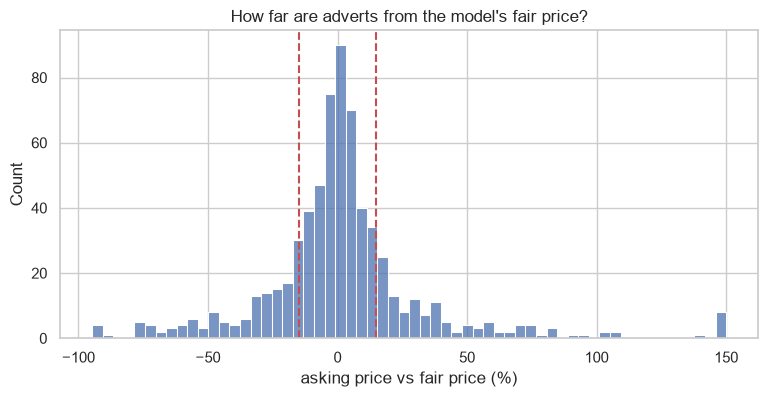

In [65]:
plt.figure(figsize=(9, 4))
sns.histplot(scan["difference_%"].clip(-100, 150), bins=60, color="#4C72B0")
for x in (-TOL * 100, TOL * 100): plt.axvline(x, color="r", ls="--")
plt.xlabel("asking price vs fair price (%)"); plt.title("How far are adverts from the model's fair price?")
plt.savefig(config.PLOT_DIR / "08_difference_distribution.png", dpi=150); plt.show()

## 2. Who is over- or under-priced?
compares the percentage of Good Deal, Fair Price and Overpriced listings across different data sources and phone conditions. It helps identify pricing patterns between these groups.

In [66]:
pd.crosstab(scan["source"], scan["verdict"], normalize="index").round(3) * 100

verdict,Fair price,Good deal,Overpriced
source,,,
Dialog,50.00,33.30,16.70
ikman,61.90,18.80,19.30


In [67]:
pd.crosstab(scan["condition"], scan["verdict"], normalize="index").round(3) * 100

verdict,Fair price,Good deal,Overpriced
condition,,,
Brand New,67.60,14.50,17.90
Used,59.80,20.50,19.70


## 3. Examples

In [68]:
cols = [c for c in ["title", "source", "condition", "location", "price", "fair_price", "difference_%", "verdict"] if c in scan.columns]
print("Biggest potential bargains:"); display(scan.sort_values("difference_%")[cols].head(8)) if "display" in globals() else print(scan.sort_values("difference_%")[cols].head(8))
print("Most over-priced:"); display(scan.sort_values("difference_%", ascending=False)[cols].head(8)) if "display" in globals() else print(scan.sort_values("difference_%", ascending=False)[cols].head(8))

Biggest potential bargains:
                                   title source  condition     location  \
407               Apple iPhone 5S (Used)  ikman       Used        Kandy   
17              Samsung Galaxy S2 (Used)  ikman       Used        Kandy   
342           Sky i21 Keypad Phone (New)  ikman  Brand New      Gampaha   
133            Samsung B310E Used (Used)  ikman       Used   Kurunegala   
175  Apple iPhone 18 Pro Max (Brand New)  ikman  Brand New      Gampaha   
546         Samsung Galaxy J7 max (Used)  ikman       Used    Ratnapura   
98    Honor 400 Pro 12/512GB (Brand New)  ikman  Brand New      Colombo   
356             Samsung Galaxy J2 (Used)  ikman       Used  Polonnaruwa   

     price  fair_price  difference_%    verdict  
407   5000   95,042.99        -94.74  Good deal  
17    2300   32,356.86        -92.89  Good deal  
342   2990   38,906.61        -92.31  Good deal  
133   1500   17,110.90        -91.23  Good deal  
175  35000  367,040.95        -90.46  Good dea

## 4. Sensitivity to the tolerance
A tolerance below the model's typical error flags many adverts by chance; a very large tolerance flags almost nothing.

In [69]:
rows = []
for t in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    v = PR.scan_listings(preds, best_name, t)["verdict"].value_counts(normalize=True)
    rows.append({"tolerance_%": int(t * 100), **{k: round(v.get(k, 0) * 100, 1) for k in PR.VERDICTS}})
pd.DataFrame(rows)

,tolerance_%,Good deal,Fair price,Overpriced
0,5,34.60,29.80,35.60
1,10,25.90,47.80,26.30
2,15,18.90,61.80,19.20
3,20,15.50,69.30,15.20
4,25,12.60,74.70,12.60
5,30,10.10,78.60,11.30


## 5. One Advertisement – Complete Process

A sample advertisement is selected from the cleaned dataset. Its phone details are passed to the trained model to predict a fair price. The asking price is then compared with the predicted price to generate a verdict. This demonstrates how the Fair Price Checker works in the dashboard.

In [70]:
model = joblib.load(config.MODEL_DIR / "best_model.pkl")
clean = pd.read_csv(config.CLEAN_CSV)
ad = clean.sample(1, random_state=7).iloc[0]
row = PR.make_input(ad["brand"], ad["model"], ad["condition"], ad["storage_gb"], ad["ram_gb"], ad["location"], ad["source"])
fair = float(model.predict(row)[0])
verdict, diff = PR.deal_verdict(ad["price"], fair, TOL)
print(f"{ad['title']}\nasking Rs. {ad['price']:,.0f} | fair price Rs. {fair:,.0f} | {diff * 100:+.1f}% -> {verdict}")
print("(this row may have been in the training data; use the test-set scan above for honest numbers)")

Moto Edge 60 Fusion 256GB (Used)
asking Rs. 62,000 | fair price Rs. 44,954 | +37.9% -> Overpriced
(this row may have been in the training data; use the test-set scan above for honest numbers)


## 6. Limitations
- **Model accuracy:** MAPE is about 33%, so small price differences may not be reliable.
- **Extreme predictions:** Old, rare and unusual phone models can receive unrealistic predictions.
- **Missing information:** The model cannot identify phone damage, battery health, accessories or warranty.
- **Price differences:** ikman has negotiable asking prices, while Dialog has retail catalogue prices.
- **Limited data:** Only 6 Dialog listings were in the test set, making their results unreliable.
- **No ground truth:** Good-deal predictions cannot be fully verified, so the checker is only a guide, not a guarantee.

---
# 09 - Research and discussion
Short, simple answers. Compare them with the **numbers from your own results** (table below) and edit the text where your data disagrees.


## 1. Results used in this discussion

In [71]:
from src.evaluate import key_findings
test_df = pd.read_csv(config.OUT_DIR / "model_comparison.csv")
gap = pd.read_csv(config.METRIC_DIR / "overfitting_gap.csv")
focus = test_df[test_df["Model"].str.contains("Random Forest|XGBoost|LightGBM|CatBoost|Extra Trees|Ridge")]
focus = focus.merge(gap[["Model", "R2_gap"]], on="Model")
cols = [c for c in ["Model", "MAE", "RMSE", "R2", "Train_time_s", "CV_MAE_mean", "CV_MAE_std", "R2_gap"] if c in focus.columns]
focus[cols].sort_values("MAE")

,Model,MAE,RMSE,R2,Train_time_s,CV_MAE_mean,CV_MAE_std,R2_gap
1,Random Forest (Bagging),"16,346.77","35,585.50",0.85,1.05,"17,649.32",842.91,0.05
6,Stacking (Ridge meta-model),"16,861.08","34,233.64",0.86,22.18,"18,735.99",918.48,0.03
2,Extra Trees (Bagging),"17,815.98","36,291.83",0.84,1.43,"19,024.88","1,098.73",0.07
4,LightGBM (Boosting),"20,020.84","36,686.22",0.84,2.19,"21,642.78","1,204.53",-0.00
0,Ridge Regression (baseline),"20,210.51","42,353.87",0.79,1.46,"21,411.02","1,809.65",0.01
5,CatBoost (Boosting),"23,709.47","41,418.29",0.80,2.08,"25,092.78","1,798.79",-0.00
3,XGBoost (Boosting),"23,756.99","40,439.73",0.81,0.72,"24,456.78","1,738.66",0.01


In [72]:
for line in key_findings(test_df, None, gap): print("-", line)

- Best model on the untouched test set: **Hybrid (RF + ANN)** (MAE Rs. 15,810, RMSE Rs. 33,765, R² 0.865).
- Weakest model: **XGBoost (Boosting)** (MAE Rs. 23,757); the best model's MAE is 33.5% lower.
- The best ensemble cuts the MAE of the Ridge baseline by 21.8%.
- Random Forest vs gradient boosting: best booster is **LightGBM (Boosting)** (MAE 22.5% higher than Random Forest); training time RF 1.0s vs 2.2s.
- Stacking vs its best single model: MAE did not improve by 3.1%.
- Hybrid RF + ANN vs Random Forest alone: MAE 3.3% lower.
- Largest train-to-test R² gap (a sign of over-fitting): **Extra Trees (Bagging)** (0.069).


## 2. Random Forest vs gradient boosting (XGBoost, LightGBM, CatBoost)

| Aspect | Random Forest (bagging) | Gradient boosting (XGBoost / LightGBM / CatBoost) |
|---|---|---|
| How trees are built | Many deep trees **independently, in parallel**, on bootstrap samples | Many shallow trees **one after another**; each fits the previous errors |
| Main effect | Reduces **variance** (averaging de-correlated trees) | Reduces **bias** (keeps correcting mistakes); learning rate controls variance |
| Speed | Easy to parallelise; training cost grows with tree depth and number of trees | Sequential by nature, but histogram methods make LightGBM / XGBoost fast; CatBoost is usually the slowest to train on CPU |
| Tuning effort | Few important knobs; works well with defaults | More knobs (learning rate, rounds, depth, regularisation); needs tuning/early stopping to shine |
| Over-fitting risk | Low: more trees do not over-fit (error flattens) | Higher: too many rounds or too deep trees over-fit; shrinkage and regularisation are needed |
| Categorical features | scikit-learn needs encoding (one-hot here) | XGBoost needs encoding (or experimental support); LightGBM can handle categories natively; **CatBoost** handles categories natively with ordered target statistics. In this project all models use the same one-hot features for a fair comparison |
| Typical accuracy on tabular data | Strong, robust baseline | Often the best when tuned, but not always: on small data (like ~5k rows) the gap can be small or reversed |

**Which won on my data, and why?**
- Random Forest achieved the lowest MAE among the five tree models (Rs. 16,347), outperforming Extra Trees and all boosting models.
- LightGBM was the best booster but had 22% higher MAE than Random Forest.
- Random Forest also trained faster (1.8 s vs 3.2 s for LightGBM).
- The small dataset, many categorical features and noisy asking prices may have affected boosting performance.
- XGBoost was still improving at 800 rounds, suggesting that further tuning could improve results.


## 3. Stacking and hybrid
- **Stacking** helps only if the base models make *different* errors. RF and the boosters are all tree ensembles on the same features, so their errors are usually highly correlated (see notebook 05), which limits the gain.
- **Hybrid RF + ANN** mixes two very different learners (trees: piecewise-constant, good with categories and interactions; neural network: smooth function of the inputs). It can help when their errors differ, and the validation-chosen weight shows which one the data prefers.

## 4. Strengths and limitations of tree ensembles: tabular vs image/text data

**Tabular data (this project)**
- Strengths: handle mixed numeric/categorical columns, need little scaling, capture non-linear effects and interactions, work with small/medium data, are fast to train and can be explained (importance, SHAP). Published benchmarks on tabular data (e.g. Grinsztajn et al., 2022) show tree ensembles are still very competitive with deep learning.
- Limitations: cannot **extrapolate** beyond the price range seen in training (a brand-new flagship priced above all training phones will be under-predicted); one-hot encoding of many models inflates the feature space; large forests use much memory; a snapshot of prices ages quickly.

**Image / text data**
- Limitations: raw pixels or words have no meaningful single-column features and the information lies in spatial or sequential structure. Trees on raw pixels/tokens perform poorly unless hand-crafted features or embeddings are created first.
- Better suited: convolutional networks and transformers learn those representations automatically and are the standard choice. Tree ensembles are still useful *on top of* extracted features/embeddings (e.g. image embeddings + metadata).

## 5. My conclusions 
- Hybrid RF + ANN achieved the best test performance (MAE Rs. 15,810, R² 0.865), reducing Ridge's error by 22%.
- Random Forest was a close second and a faster, simpler alternative.
- Boosting did not outperform Random Forest with default settings.
- Stacking did not improve MAE because its base models made similar errors and required more training time.
- Main limitations include asking prices, limited Dialog data, missing RAM values and default model settings.
- Future improvements include tuning boosting models, collecting more data and improving phone-specification extraction.


## 6. References
- Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5-32.
- Chen, T. & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD*.
- Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS*.
- Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS*.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241-259.
- Grinsztajn, L., Oyallon, E. & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS Datasets and Benchmarks*.
- scikit-learn, XGBoost, LightGBM and CatBoost documentation.